In [15]:
%pip install -q matplotlib tensorflow numpy pillow scikit-image


[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Module 8 Capstone Project Part 1

> Submitted by Phillip Amir Esguerra

# 1. Import Libraries

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import math
from PIL import Image
import tensorflow as tf
from keras import (
    layers,
    models,
    optimizers,
    utils,
    callbacks,
    metrics,
    losses,
    activations,
)
from skimage import data, color, img_as_float

# Load and display sample image

In [ ]:
input_image_path = r"./input.png"
input_image = Image.open(input_image_path)
input_image_float = np.array(input_image)
timesteps = [0.1, 0.3, 0.6, 0.9]

In [53]:
def display_image(image_as_float, title="", size=(5, 5)):
    plt.figure(figsize=size)
    plt.imshow(image_as_float)
    plt.axis('off')
    plt.title(title)
    plt.show()
    
    return image_as_float

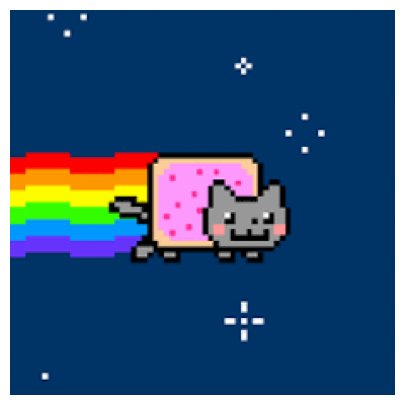

In [50]:
display_image(input_image_float)

# Adding Noise

In [ ]:
def add_noise(image, timestep): # deepfrying :)
    alpha_bar = 1 - timestep # basically a linear schedule
    noise = np.random.normal(0, 1, image.shape)
    noisy_image = np.sqrt(alpha_bar) * image + np.sqrt(1 - alpha_bar) * noise
    return np.clip(noisy_image, 0, 1)

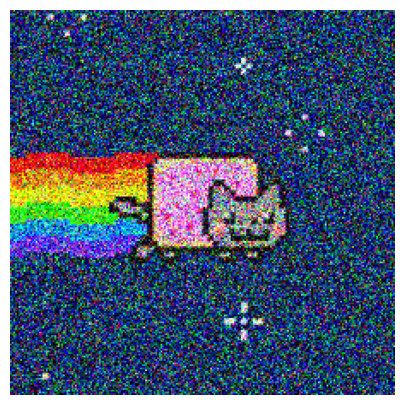

In [78]:
_ = display_image(add_noise(image=input_image_float, timestep=0.1))

# Visualizing noise by timestep

In [100]:
def display_noise_by_timestep(image, timesteps, title="", size=(15, 4)):
    figure, axes = plt.subplots(1, len(timesteps), figsize=size)
    axes = axes.flatten()
    figure.suptitle(title)
    for i, t in enumerate(timesteps):
        noisy_image = add_noise(image=input_image_float, timestep=t)
        axes[i].imshow(noisy_image)
        axes[i].set_title(f"t: {t}")
        axes[i].axis('off')

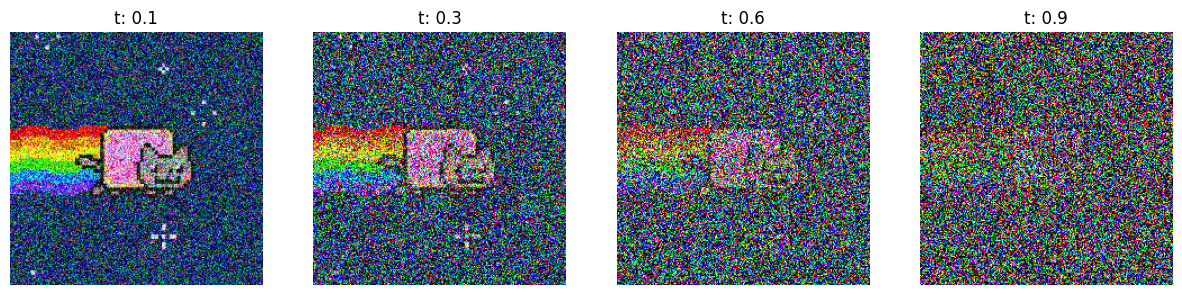

In [102]:
display_noise_by_timestep(image=input_image_float, timesteps=timesteps)

# Implementing Noise Schedules

In [81]:
def linear_alpha_bar(timestep):
    return 1 - timestep

def cosine_alpha_bar(timestep):
    return tf.cos((timestep + 0.008) / 1.008 * math.pi / 2) ** 2

def cosine_alpha_bar2(timestep):
    return tf.cos(timestep * math.pi / 2)

def exponential_alpha_bar(timestep):
    beta_min = 0.0001
    beta_max = 0.02
    alpha_bar = np.exp(-0.5 * (beta_min + beta_max) * timestep)
    return alpha_bar

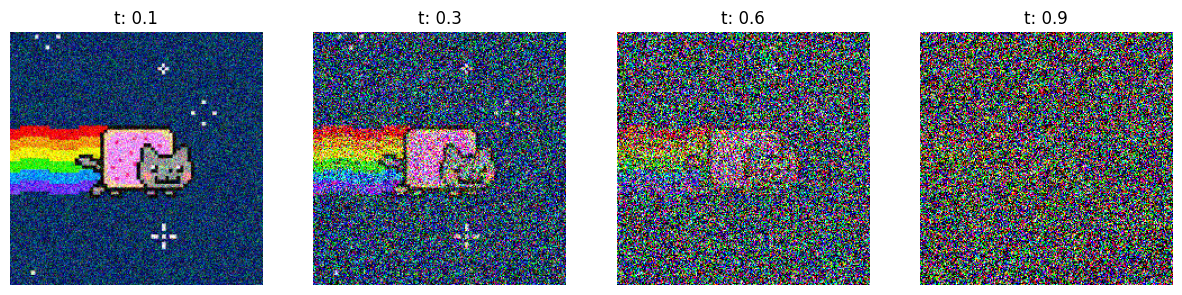

In [ ]:
def add_noise_with_schedule(image, timestep, schedule_fn): # deepfrying :)
    alpha_bar = schedule_fn(timestep)
    noise = np.random.normal(0, 1, image.shape)
    noisy_image = np.sqrt(alpha_bar) * image + np.sqrt(1 - alpha_bar) * noise
    return np.clip(noisy_image, 0, 1)

def display_noise_by_timestep(image, timesteps, title="", size=(15, 3), schedule_fn=None):
    figure, axes = plt.subplots(1, len(timesteps), figsize=size)
    axes = axes.flatten()
    figure.suptitle(title)
    for i, t in enumerate(timesteps):
        noisy_image = add_noise_with_schedule(image=input_image_float, timestep=t, schedule_fn=schedule_fn)
        axes[i].imshow(noisy_image)
        axes[i].set_title(f"t: {t}")
        axes[i].axis('off')

display_noise_by_timestep(
    image=input_image_float, 
    timesteps=[0.0, 0.2, 0.4, 0.6, 0.8], 
    title="Noisy Images at Different Tim